# Statistical Arbitrage in Cryptocurrencies — 13 coins, Binance global

**Goal (from the project brief):** research profitable momentum and/or reversal strategies in crypto, net of realistic execution costs, combine them, and evaluate the result.

This notebook redoes `project_final_v2.ipynb` (the 13 Binance.US coins) with the method of `30coins_project.ipynb`: **Binance global data**, Sharpe on daily returns × √252, a **train / test split** (training Apr-2021 → Aug-2025, every choice made there by the same rules; test Sep-2025 → Oct-2026), and a final section on handling strategy failure. The only difference from v3 is the universe: the fixed 13 coins instead of a monthly top 30.

**Summary of findings** (final strategy: XS momentum + TS momentum + fire sale + betting against beta, risk parity; net of 20 bps)

| | net Sharpe | beta to BTC | alpha vs BTC (t-stat) |
|---|---|---|---|
| Training, Apr-2021 → Aug-2025 | **1.41** (max drawdown −12%) | 0.06 | 15.0% / yr (3.4) |
| **Test, Sep-2025 → Oct-2026** | **0.84** | 0.02 | 5.8% / yr (1.2) |
| &nbsp;&nbsp;Sep–Dec 2025 | 3.07 | 0.01 | 21.2% / yr (2.2) |
| &nbsp;&nbsp;2026 Jan–Oct | −0.10 | 0.03 | −0.5% / yr (−0.1) |

- **XS momentum failed in 2026 with 13 coins** (−1.13: low dispersion, negative rank IC), while it worked with 30 coins (+1.09).
- **BAB worked in 2026 with 13 coins** (+0.83), while it failed with 30 coins (−2.82).
- **Pairs trading** is profitable on Binance.US (net 0.15) but not on Binance global (−0.12).
- **Handling failure (Section 12):** the 30% cap and rolling max-Sharpe weights do *not* help here (test 0.75 and 0.66 vs 0.83), because the failing strategy (XS) did not hold the most capital.
- Caveat: the 13 coins were chosen with full-sample volume, and the v2 design overlaps the test period; see Section 13.

**Contents**
0. Setup and helper functions
1. Data and universe
2. Momentum: time horizon
3. Transaction costs and execution
4. A better cross-sectional momentum signal
5. Momentum and activity (volume)
6. Time-series momentum
7. Reversal (7.1 short-term reversal, 7.2 pairs trading, 7.2.1 Binance.US vs global, 7.3 fire sale)
8. Betting against beta
9. Combining the strategies
10. Performance evaluation (training period)
11. Test period
12. Handling strategy failure: rolling max-Sharpe weights and a 30% cap
13. Conclusions and limitations


## 0. Setup and helper functions

*All functions and constants are in `statarb.py`, shared with the other universe's notebook; each function receives the universe (`univ`), the market (`mkt`) and the equal-weight weights (`ew`) as arguments.*

This notebook redoes `project_final_v2.ipynb` (13 coins) with the method of `30coins_project.ipynb` (30-coin point-in-time universe), so that the two can be compared directly:
- **same data source**: Binance global (v2 developed the strategy on Binance.US, whose volume collapsed in 2026);
- **same train / test split**: training Apr-2021 → Aug-2025, every choice made there; test Sep-2025 → Oct-2026;
- **same code and decision rules** as v3; the only difference is the universe: **the fixed 13 coins of v2** (a coin is in the universe whenever it has a price).

Conventions:
- 4-hour bars; `held = w.shift(lag)` is the position during each bar (no look-ahead).
- Costs: 20 bps per unit traded (market orders), 7 bps (limit orders).
- Sharpe on **daily-aggregated** returns, annualized with **√252**.
- None of the 13 coins stops trading during the sample, so the rule for delisted coins in `backtest()` never applies.

In [1]:
import itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

from statarb import *          # all functions, and COST, COST_LIMIT, DAYS_PER_YEAR, EVAL_START, TRAIN_END, TEST_START, SETS

COINS = list(pd.read_pickle('data/px_liquid_1h.pk').columns)      # the 13 coins of project_final_v2
px_all = pd.read_pickle('data/global30_px_1h.pk')[COINS]          # Binance global 1h close, Jan-2020 -> Oct-2026
ret_all = px_all.resample('4h').last().pct_change(fill_method=None)
univ_all = ret_all.notna()                                        # fixed universe: a coin is in it whenever it has a price

# Sections 2-10 use the training period only: the data are cut at 31-Aug-2025
ret  = ret_all.loc[:TRAIN_END]
univ = univ_all.loc[:TRAIN_END]
print('training data:', ret.index.min(), '->', ret.index.max(), '|', ', '.join(c.replace('USDT', '') for c in COINS))

training data: 2020-01-01 00:00:00 -> 2025-08-31 20:00:00 | BTC, ETH, SOL, ADA, BNB, DOGE, VET, LTC, AVAX, ATOM, XLM, LINK, HBAR


In [2]:
mkt = (equal_weight(univ).shift(1)*ret).sum(axis=1)       # equal-weight market of the universe
btc = ret['BTCUSDT']
pd.DataFrame({'equal-weight market (13 coins)': perf(mkt.loc[EVAL_START:], mkt),
              'BTC': perf(btc.loc[EVAL_START:], mkt)}).T.round(3)

,Sharpe,annual return,annual vol,max drawdown,beta
equal-weight market (13 coins),0.530,0.342,0.646,-1.419,1.000
BTC,0.437,0.208,0.476,-1.255,0.621


## 1. Data and universe

The 13 coins of `project_final_v2.ipynb`: the Binance.US coins with a median volume of at least \$1,000 per hour over 2020–2025 (XRP and MATIC dropped). Prices here are from **Binance global** (`data.binance.vision`), the same data as the 30-coin version.

*Caveat:* the 13 coins were chosen with full-sample Binance.US volume, i.e. with knowledge of which coins stayed liquid until 2025 (look-ahead and survivorship in the universe). The 30-coin version selects coins each month from past volume only.

In [3]:
vol_all = pd.read_pickle('data/global30_vol_1h.pk')[COINS]
pd.DataFrame({'first price': px_all.apply(lambda s: s.first_valid_index()),
              'last price':  px_all.apply(lambda s: s.last_valid_index()),
              'median $vol/hour, Binance global (training)': vol_all.loc[:TRAIN_END].median().round(0)}).sort_values('median $vol/hour, Binance global (training)', ascending=False)

,first price,last price,"median $vol/hour, Binance global (training)"
BTCUSDT,2020-01-01 00:00:00,2026-10-31 23:00:00,64613123.0
ETHUSDT,2020-01-01 00:00:00,2026-10-31 23:00:00,32205187.0
SOLUSDT,2020-08-11 06:00:00,2026-10-31 23:00:00,8434411.0
BNBUSDT,2020-01-01 00:00:00,2026-10-31 23:00:00,5368962.0
DOGEUSDT,2020-01-01 00:00:00,2026-10-31 23:00:00,3180655.0
ADAUSDT,2020-01-01 00:00:00,2026-10-31 23:00:00,2409846.0
LINKUSDT,2020-01-01 00:00:00,2026-10-31 23:00:00,2218194.0
AVAXUSDT,2020-09-22 06:00:00,2026-10-31 23:00:00,1929943.0
LTCUSDT,2020-01-01 00:00:00,2026-10-31 23:00:00,1768351.0
ATOMUSDT,2020-01-01 00:00:00,2026-10-31 23:00:00,714664.0


**Train / test split (80 / 20):** warm-up Apr-2020 → Mar-2021 (signals and risk-parity weights need history); **training Apr-2021 → Aug-2025**: every choice in Sections 2–10 is made here, on data cut at 31-Aug-2025; **test Sep-2025 → Oct-2026** (Section 11), run with the same code and no change of parameters.

## 2. Momentum: time horizon

Same test as Section 2 of the 13-coin notebook: rank the coins in the universe on their average return over the last *h* hours, long winners / short losers (demeaned ranks, dollar neutral, Σ|w| = 1), rebalanced every 4h, **no costs yet**. Two delays: `shift(1)` and `shift(2)` (skip one bar).

In [4]:
hours = [4, 8, 12, 24, 72, 168, 336, 720]
gross_h = {}
for h in hours:
    w = xs_momentum(ret, h, univ)
    for lag in [1, 2]:
        gross_h[(h, lag)] = backtest(w.shift(lag), ret)[0]
gross_h = pd.DataFrame(gross_h).loc[EVAL_START:]

sharpe(gross_h).unstack().rename(columns={1: 'no skip (shift 1)', 2: 'skip 1 bar (shift 2)'}).round(2)

,no skip (shift 1),skip 1 bar (shift 2)
4,-1.34,0.13
8,-0.35,0.68
12,-0.22,1.38
24,0.49,0.73
72,1.05,0.97
168,1.03,1.34
336,1.08,1.20
720,0.85,0.94


,4,8,12,24,72,168,336,720
2021,1.34,1.14,1.90,1.49,1.38,1.58,1.21,1.46
2022,-1.72,-0.70,0.58,1.09,1.63,1.98,1.97,1.00
2023,-0.57,-0.27,1.77,0.45,0.94,1.66,1.07,1.26
2024,0.45,2.00,2.24,0.72,1.29,1.52,1.33,0.88
2025,0.65,0.54,-0.04,-0.90,-1.44,-0.50,0.23,-0.35


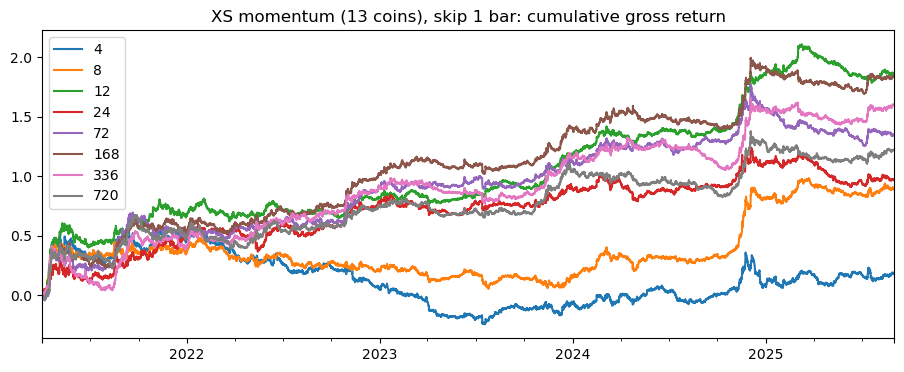

In [5]:
# stability: gross Sharpe by year (skip 1 bar)
g2 = gross_h.xs(2, axis=1, level=1)
display(g2.groupby(g2.index.year).apply(sharpe).round(2))
g2.cumsum().plot(figsize=(11, 4), title='XS momentum (13 coins), skip 1 bar: cumulative gross return');

**Conclusion (training period, Apr-2021 → Aug-2025, gross).**
- The equal-weight 13-coin market has a Sharpe of 0.53 (vol 65%), above BTC (0.44): the 13 coins are large coins that survived (selected with full-sample volume).
- Short-horizon reversal (h=4, no skip: −1.34).
- Skipping one bar, momentum is positive at every horizon; the best are h=12 (1.38, but costly), **h=168 (1.34) and h=336 (1.20)**; h=720 is 0.94. Momentum is positive in 2021–2024 at the slow horizons but **negative in Jan–Aug 2025** for most of them: the 13-coin momentum was already fading before the test period.


## 3. Transaction costs and execution

Same steps as Section 3 of the 13-coin notebook, on the training period only. New column **`turnover from coin replacement`**: the share of turnover that comes from coins entering or leaving the universe (selling a coin that drops out, buying one that comes in).

### 3.1 Costs with 4-hourly rebalancing

In [6]:
gross_c, to_c, sw_c = {}, {}, {}
for h in hours:
    held = xs_momentum(ret, h, univ).shift(2)
    gross_c[h], to_c[h] = backtest(held, ret)
    sw_c[h] = replacement_turnover(held, 2, univ)
cost_table_u(pd.DataFrame(gross_c), pd.DataFrame(to_c), pd.DataFrame(sw_c)).round(3)

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps),turnover from coin replacement
4,0.130,-19.362,-6.705,1.346,0.134,0.0
8,0.683,-13.219,-4.262,0.954,0.961,0.0
12,1.378,-9.836,-2.607,0.791,2.410,0.0
24,0.726,-7.408,-2.176,0.573,1.739,0.0
72,0.965,-3.716,-0.694,0.342,4.063,0.0
168,1.339,-1.920,0.191,0.232,8.172,0.0
336,1.201,-1.201,0.356,0.166,9.957,0.0
720,0.943,-0.735,0.355,0.113,11.224,0.0


### 3.2 Rebalance less often

The signal is still computed every 4h, but the position is only updated once a day (00:00 UTC) or once a week (Monday 00:00) and held in between. The universe changes on the 1st of the month at 00:00, which is also a daily rebalance time.

In [7]:
rebalance = {'every 4h': np.ones(len(ret), dtype=bool),
             'daily':    ret.index.hour == 0,
             'weekly':   (ret.index.dayofweek == 0) & (ret.index.hour == 0)}

gross_f, to_f, sw_f = {}, {}, {}
for freq, mask in rebalance.items():
    for h in hours:
        held = hold_at(xs_momentum(ret, h, univ), mask).shift(2)
        gross_f[(freq, h)], to_f[(freq, h)] = backtest(held, ret)
        sw_f[(freq, h)] = replacement_turnover(held, 2, univ)
freq_table = cost_table_u(pd.DataFrame(gross_f), pd.DataFrame(to_f), pd.DataFrame(sw_f))
for col, fmt in [('net Sharpe (20bps)', '{:.2f}'), ('breakeven (bps)', '{:.1f}'), ('turnover from coin replacement', '{:.1%}')]:
    display(freq_table[col].unstack(0)[list(rebalance)]
            .rename_axis(index='lookback h (hours)', columns='rebalance')
            .style.format(fmt).set_caption(f'XS momentum (13 coins): {col} by rebalance frequency'))

rebalance,every 4h,daily,weekly
lookback h (hours),,,
4,-19.36,-1.95,-0.26
8,-13.22,-2.29,-0.22
12,-9.84,-2.17,0.14
24,-7.41,-2.57,-0.11
72,-3.72,-0.38,-0.10
168,-1.92,0.18,0.28
336,-1.20,0.41,0.01
720,-0.74,0.37,-0.24


rebalance,every 4h,daily,weekly
lookback h (hours),,,
4,0.1,8.0,9.6
8,1.0,6.8,11.2
12,2.4,7.0,25.4
24,1.7,4.8,15.5
72,4.1,15.8,15.7
168,8.2,23.0,31.1
336,10.0,29.1,20.8
720,11.2,31.3,1.0


rebalance,every 4h,daily,weekly
lookback h (hours),,,
4,0.0%,0.0%,0.0%
8,0.0%,0.0%,0.0%
12,0.0%,0.0%,0.0%
24,0.0%,0.0%,0.0%
72,0.0%,0.0%,0.0%
168,0.0%,0.0%,0.0%
336,0.0%,0.0%,0.0%
720,0.0%,0.0%,0.0%


In [8]:
# robustness: does the daily result depend on the hour of the day we rebalance? (net Sharpe, 20 bps)
rob_hour = {}
for hr in range(0, 24, 4):
    for h in [168, 336, 720]:
        g, t = backtest(hold_at(xs_momentum(ret, h, univ), ret.index.hour == hr).shift(2), ret)
        rob_hour[(hr, h)] = sharpe((g - COST*t).loc[EVAL_START:])
pd.Series(rob_hour).unstack().rename_axis(index='rebalance hour', columns='h').round(2)

h,168,336,720
rebalance hour,,,
0,0.18,0.41,0.37
4,-0.02,0.19,0.34
8,-0.02,0.23,0.27
12,-0.04,0.16,0.35
16,-0.10,0.12,0.32
20,-0.28,-0.00,0.30


### 3.3 Optimization with a transaction-cost penalty (cvxpy)

Same problem as in `project_final_v2.ipynb`, every day at 00:00:

$$\min_w \;(w-w^*)^\top \Sigma\,(w-w^*) \;+\; \lambda \cdot c \cdot \lVert w - w_{prev}\rVert_1 \quad \text{s.t.}\quad \textstyle\sum_i w_i = 0,\;\; \lVert w\rVert_1 \le 1$$

Only change: it is solved **over the coins in today's universe**. A coin that left the universe is sold (weight 0); this cost does not depend on $w$, so it does not change the solution, but it is counted in turnover. Σ = Ledoit-Wolf covariance of the past 30 days of the coins in the universe.

λ = 0 must reproduce the daily rule of 3.2 (sanity check). Run for h = 336 and 720, the two slow horizons that survive costs.

In [9]:
gross_o, to_o, sw_o = {}, {}, {}
for h in [336, 720]:
    for pen in [0, 0.001, 0.003, 0.01]:
        held = rolling_opt(xs_momentum(ret, h, univ), ret, univ, tc_penalty=pen).reindex(ret.index).ffill().shift(2)
        gross_o[(h, pen)], to_o[(h, pen)] = backtest(held, ret)
        sw_o[(h, pen)] = replacement_turnover(held, 2, univ)
opt_table = cost_table_u(pd.DataFrame(gross_o), pd.DataFrame(to_o), pd.DataFrame(sw_o))
opt_table.index.names = ['h', 'tc_penalty']
opt_table.round(3)

gross Sharpe  net Sharpe (20bps)  net Sharpe (7bps)  avg turnover  breakeven (bps)  turnover from coin replacement
h   tc_penalty                                                                                                                    
336 0.000              1.319               0.411              1.001         0.062           29.088                             0.0
    0.001              1.271               0.582              1.030         0.046           36.978                             0.0
    0.003              1.156               0.669              0.986         0.032           47.617                             0.0
    0.010              0.944               0.685              0.853         0.015           73.003                             0.0
720 0.000              1.024               0.368              0.794         0.044           31.251                             0.0
    0.001              0.964               0.506              0.804         0.030           42.112                             0.0
    0.003              0.921               0.628              0.818         0.019           62.879                             0.0
    0.010              0.498               0.359              0.449         0.008           71.771                             0.0

In [10]:
# stability of the cost-aware momentum: net Sharpe (20 bps) by year
net_o = (pd.DataFrame(gross_o) - COST*pd.DataFrame(to_o)).loc[EVAL_START:]
net_o.groupby(net_o.index.year).apply(sharpe).round(2)

336                     720                  
     0.000 0.001 0.003 0.010 0.000 0.001 0.003 0.010
2021  0.85  0.90  0.97  0.94  1.17  1.18  1.17  1.24
2022  0.99  1.07  1.13  0.55  0.29  0.45  0.55  0.15
2023 -0.05  0.23  0.12  0.22  0.71  0.95  1.22  0.69
2024  0.64  0.83  1.07  1.29  0.11  0.27  0.34 -0.03
2025 -1.10 -0.65 -0.46 -0.05 -1.12 -0.88 -0.58 -1.02

**Conclusion (training period).**
- Every 4h, costs kill everything (best break-even 11 bps < 20 bps).
- Daily: h=336 → **0.41** net, h=720 → 0.37, h=168 → 0.18; weekly loses signal. h=720 does not depend on the rebalance hour (0.27–0.37); h=336 does more (0.00–0.41).
- **cvxpy:** h=720, λ = 0.003 → **0.63** (turnover 0.044 → 0.019, break-even 63 bps); λ = 0 reproduces the daily rule (0.37). **With 13 coins h=336 beats h=720 for every λ** (λ = 0.003: 0.67), the opposite of the 30-coin version; the final signal of Section 4 combines 168, 336 and 720 hours, so it does not depend on this choice.
- All settings lose money in Jan–Aug 2025 (−0.05 to −1.12).


## 4. A better cross-sectional momentum signal

Same two changes as Section 4 of the 13-coin notebook, applied to the h = 720 signal:
1. **Multi-horizon**: average the ranks of h = 168, 336, 720 (1 week, 2 weeks, 1 month) instead of picking one horizon.
2. **Volatility-adjusted**: rank on past return ÷ past 30-day volatility, so a coin does not rank high just because it is volatile. This matters more with 13 coins: many newly listed coins are very volatile.

Ranks are taken **among the coins in the universe only**. Then the same daily rebalance + cvxpy (λ = 0.003).

In [11]:
# each change separately, then both (daily rebalance without optimizer, and with cvxpy)
signals = {'h=720':                        xs_momentum(ret, 720, univ),
           'h=720, vol-adjusted':          xs_momentum_mhva(ret, univ, horizons=(720,)),
           'multi-horizon':                norm(sum(xs_momentum(ret, h, univ).replace(0, np.nan).rank(axis=1) for h in (168, 336, 720)) / 3, univ),
           'multi-horizon + vol-adjusted': xs_momentum_mhva(ret, univ)}
daily = ret.index.hour == 0
gross_s, to_s, sw_s = {}, {}, {}
for name, w in signals.items():
    held = hold_at(w, daily).shift(2)
    gross_s[('daily', name)], to_s[('daily', name)] = backtest(held, ret)
    sw_s[('daily', name)] = replacement_turnover(held, 2, univ)
for name in ['h=720', 'multi-horizon + vol-adjusted']:
    W = rolling_opt(signals[name], ret, univ, tc_penalty=0.003)
    held = W.reindex(ret.index).ffill().shift(2)
    gross_s[('cvxpy 0.003', name)], to_s[('cvxpy 0.003', name)] = backtest(held, ret)
    sw_s[('cvxpy 0.003', name)] = replacement_turnover(held, 2, univ)
    if name != 'h=720':
        W_xs = W                                  # kept: this is the candidate final XS strategy
xs_table = cost_table_u(pd.DataFrame(gross_s), pd.DataFrame(to_s), pd.DataFrame(sw_s))
xs_table.index.names = ['execution', 'signal']
xs_table.round(3)

gross Sharpe  net Sharpe (20bps)  net Sharpe (7bps)  avg turnover  breakeven (bps)  turnover from coin replacement
execution   signal                                                                                                                                          
daily       h=720                                1.024               0.369              0.794         0.044           31.287                             0.0
            h=720, vol-adjusted                  0.980               0.239              0.721         0.045           26.454                             0.0
            multi-horizon                        1.457               0.371              1.077         0.089           26.865                             0.0
            multi-horizon + vol-adjusted         1.483               0.509              1.142         0.066           30.484                             0.0
cvxpy 0.003 h=720                                0.921               0.628              0.818         0.019           62.879                             0.0
            multi-horizon + vol-adjusted         1.306               0.837              1.141         0.031           55.790                             0.0

,h=720,multi-horizon + vol-adjusted
2021,1.17,1.46
2022,0.55,0.90
2023,1.22,-0.02
2024,0.34,1.17
2025,-0.58,0.06


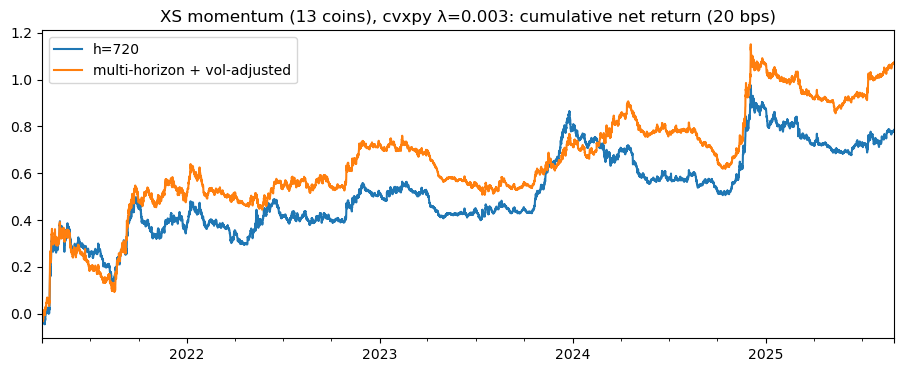

In [12]:
# stability: net Sharpe (20 bps) by year, cvxpy versions
net_s = (pd.DataFrame(gross_s) - COST*pd.DataFrame(to_s)).loc[EVAL_START:, 'cvxpy 0.003']
display(net_s.groupby(net_s.index.year).apply(sharpe).round(2))
net_s.cumsum().plot(figsize=(11, 4), title='XS momentum (13 coins), cvxpy λ=0.003: cumulative net return (20 bps)');

**Conclusion (training period).**
- **Volatility adjustment alone hurts with 13 coins** (daily h=720: 0.24 vs 0.37): the 13 coins have similar volatilities, so dividing by vol mostly adds noise (with 30 coins it was the main improvement).
- Multi-horizon alone: 0.37 (more turnover); **multi-horizon + vol-adjusted: 0.51 daily and 0.84 with the optimizer** (vs 0.63 for h=720), break-even 56 bps, the best of all the XS versions tested. Weak in 2023 (−0.02) and Jan–Aug 2025 (0.06).
- **Final XS strategy: multi-horizon + vol-adjusted, daily, cvxpy λ = 0.003** (same as v2 and the 30-coin version).


## 5. Momentum and activity (volume)

Same test as Section 5 of the 13-coin notebook. Project hypothesis: *heightened activity coupled with new information favors momentum.*

Abnormal volume of each coin, relative to its own past:

$$\text{avol}_{i,t} = \frac{\text{average 4h volume over the last } h \text{ hours}}{\text{average 4h volume over the last 90 days}}$$

Signals (h = 168 and 720): plain momentum; momentum **only among the high-avol half** of the coins in the universe; **only among the low-avol half**; and **volume-weighted** momentum (momentum rank × (1 + avol percentile)). Ranks and halves are taken among the coins in the universe. With 13 coins each half has only 6–7 coins, so splitting costs diversification.

In [13]:
vol4 = pd.read_pickle('data/global30_vol_1h.pk').loc[:TRAIN_END, ret.columns].resample('4h').sum(min_count=1)

vm = {}
for h in [168, 720]:
    avol = vol4.rolling(h//4, min_periods=h//4).mean() / vol4.rolling(540, min_periods=270).mean()
    mom = ret.rolling(h//4, min_periods=1).mean()
    valid = mom.notna() & avol.notna() & univ
    mom, avol = mom.where(valid), avol.where(valid)
    av_pct = avol.rank(axis=1, pct=True)
    high = av_pct > 0.5
    mom_rank = mom.rank(axis=1)
    vm[(h, 'plain')]           = norm(mom_rank, univ)
    vm[(h, 'high avol only')]  = norm(mom.where(high).rank(axis=1), univ)
    vm[(h, 'low avol only')]   = norm(mom.where(~high & valid).rank(axis=1), univ)
    vm[(h, 'volume-weighted')] = norm(mom_rank.sub(mom_rank.mean(axis=1), axis=0) * (1 + av_pct), univ)

vol_tab, net_vm = {}, {}
for (h, name), w in vm.items():
    g4, _ = backtest(w.shift(2), ret)                        # unconstrained, every 4h
    gd, td = backtest(hold_at(w, daily).shift(2), ret)       # daily rebalance, with costs
    net_vm[(h, name)] = (gd - COST*td).loc[EVAL_START:]
    vol_tab[(h, name)] = {'gross Sharpe (every 4h)': sharpe(g4.loc[EVAL_START:]),
                          'net Sharpe 20bps (daily)': sharpe(net_vm[(h, name)]),
                          'avg turnover (daily)': td.loc[EVAL_START:].mean()}
pd.DataFrame(vol_tab).T.round(3)

gross Sharpe (every 4h)  net Sharpe 20bps (daily)  avg turnover (daily)
168 plain                              1.339                     0.181                 0.086
    high avol only                     0.884                    -0.262                 0.105
    low avol only                      0.738                    -0.689                 0.115
    volume-weighted                    1.267                     0.157                 0.087
720 plain                              0.943                     0.369                 0.044
    high avol only                     0.709                     0.013                 0.055
    low avol only                      0.197                    -0.337                 0.063
    volume-weighted                    0.938                     0.352                 0.045

In [14]:
# by year: net Sharpe (20 bps, daily rebalance)
net_vm = pd.DataFrame(net_vm)
net_vm.groupby(net_vm.index.year).apply(sharpe).round(2)

168                                                720                                             
     plain high avol only low avol only volume-weighted plain high avol only low avol only volume-weighted
2021  0.88           0.58          0.45            0.78  1.16           0.46          0.67            1.10
2022  0.26          -0.52         -0.14            0.15  0.29           0.18         -0.25            0.30
2023  0.18          -0.64         -1.63            0.27  0.72          -0.01         -1.37            0.66
2024  0.58          -0.09         -0.45            0.51  0.11          -0.42          0.12            0.08
2025 -2.13          -1.83         -3.08           -2.01 -1.12          -0.48         -2.10           -1.00

**Conclusion (training period).** **Not supported with 13 coins.**
- Before costs, momentum among high-volume coins is a little stronger than among low-volume coins (h=168: 0.88 vs 0.74; h=720: 0.71 vs 0.20), the direction of the hypothesis, but **plain momentum is better than both halves** (1.34 and 0.94): with 6–7 coins per half, splitting costs more diversification than the volume information adds.
- After costs (daily) every volume variant is below plain momentum (h=720: high-avol 0.01, volume-weighted 0.35, plain 0.37). Not used.


## 6. Time-series momentum

TS momentum asks whether the **market** is trending: long if it rose over the last *L* days, short if it fell. Directional by design. Two choices for the trend indicator, and two for what is traded:

| | signal (trend of) | traded |
|---|---|---|
| **A** (13-coin method) | equal-weight market of the universe | equal-weight market of the universe |
| **B** | BTC | equal-weight market of the universe |
| **C** | BTC | BTC only |

Why BTC: it is the most liquid coin and leads the market.

Lookbacks L = 7, 14, 30, 60 days, and the **average of the four signs** (position between −1 and +1). Daily rebalance, `shift(2)`.

In [15]:
xs_net = (lambda g, t: g - COST*t)(*backtest(W_xs.reindex(ret.index).ffill().shift(2), ret))   # final XS strategy
ew = equal_weight(univ)
variants = {'A: market → market': (ts_signal(mkt), lambda s: ew.mul(s, axis=0)),
            'B: BTC → market':    (ts_signal(btc), lambda s: ew.mul(s, axis=0)),
            'C: BTC → BTC':       (ts_signal(btc), lambda s: only('BTCUSDT', s, ret))}

gross_t, to_t = {}, {}
for v, (sigs, position) in variants.items():
    for name, s in sigs.items():
        gross_t[(v, name)], to_t[(v, name)] = backtest(hold_at(position(s), daily).shift(2), ret)
gross_t, to_t = pd.DataFrame(gross_t), pd.DataFrame(to_t)
net_t = (gross_t - COST*to_t).loc[EVAL_START:]

ts_table = cost_table(gross_t, to_t)
ts_table['annual vol'] = to_daily(net_t).std()*np.sqrt(DAYS_PER_YEAR)
ts_table['max drawdown'] = net_t.apply(max_drawdown)
ts_table['corr with XS'] = net_t.corrwith(xs_net.loc[EVAL_START:])
ts_table['beta to market'] = net_t.apply(lambda x: perf(x, mkt)['beta'])
ts_table.index.names = ['variant', 'lookback']
ts_table.round(3)

gross Sharpe  net Sharpe (20bps)  net Sharpe (7bps)  avg turnover  breakeven (bps)  annual vol  max drawdown  corr with XS  beta to market
variant            lookback                                                                                                                                                 
A: market → market 7d                    0.351               0.070              0.253         0.058           25.038       0.628        -0.883         0.132          -0.135
                   14d                   0.884               0.718              0.826         0.034          107.162       0.626        -0.781         0.173          -0.075
                   30d                   0.552               0.437              0.512         0.024           96.365       0.633        -0.788         0.176           0.031
                   60d                   0.421               0.333              0.390         0.019           96.380       0.644        -0.984         0.140           0.154
                   average 7-60d         0.721               0.526              0.653         0.031           74.036       0.483        -0.567         0.201          -0.006
B: BTC → market    7d                    0.056              -0.237             -0.047         0.063            3.820       0.649        -2.323         0.047          -0.192
                   14d                   0.445               0.242              0.374         0.044           43.945       0.653        -1.191         0.088          -0.094
                   30d                   0.682               0.545              0.634         0.030          100.204       0.657        -1.011         0.105          -0.151
                   60d                   0.754               0.673              0.726         0.017          188.258       0.656        -0.878         0.109          -0.030
                   average 7-60d         0.615               0.407              0.542         0.035           59.068       0.515        -0.780         0.111          -0.117
C: BTC → BTC       7d                   -0.141              -0.539             -0.281         0.063           -7.048       0.478        -2.048         0.050          -0.109
                   14d                   0.265              -0.010              0.169         0.044           19.246       0.479        -0.854         0.079          -0.069
                   30d                   0.542               0.354              0.476         0.030           58.188       0.481        -0.747         0.095          -0.115
                   60d                   0.315               0.205              0.276         0.017           57.484       0.480        -0.924         0.067          -0.032
                   average 7-60d         0.322               0.028              0.219         0.035           21.922       0.366        -0.639         0.094          -0.081

,A: market → market,B: BTC → market,C: BTC → BTC
2021,0.98,0.63,-0.30
2022,0.25,-0.25,-0.35
2023,0.84,1.60,1.07
2024,0.86,0.36,0.14
2025,-0.38,-0.00,-0.26


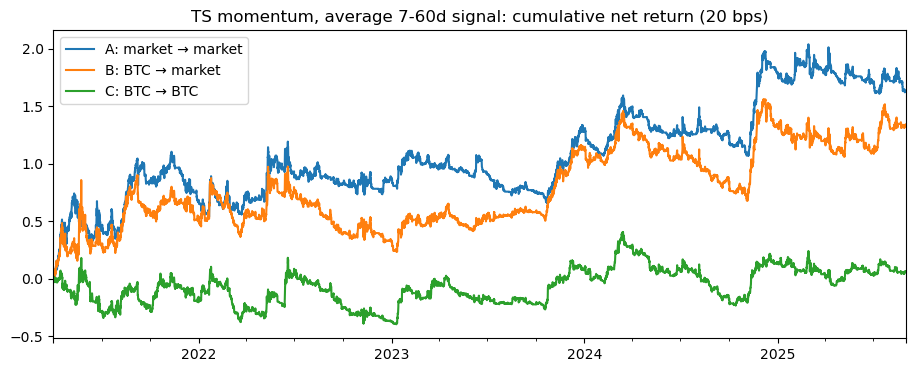

In [16]:
# stability of the averaged signals: net Sharpe (20 bps) by year
avg = net_t.xs('average 7-60d', axis=1, level=1)
display(avg.groupby(avg.index.year).apply(sharpe).round(2))
avg.cumsum().plot(figsize=(11, 4), title='TS momentum, average 7-60d signal: cumulative net return (20 bps)');

### 6.1 Market signal with the current universe (A2)

In A, the market return is the return of the equal-weight portfolio **that was held** at each bar, so after the monthly change of coins, the L-day signal is still mostly based on the coins that just left. Alternative **A2**: at time *t*, take the coins **currently** in the universe and average their own past L-day returns:

$$\text{signal}_t = \text{sign}\Big(\frac{1}{N_t}\sum_{i \in U_t} \bar r_{i,t}(L)\Big)$$

with $\bar r_{i,t}(L)$ the average 4h return of coin *i* over the last L days (average rather than sum, so a coin with a few missing bars is not dropped; the sign is the same when the window is complete). This is closer to the idea of TS momentum: *is the basket I am about to hold trending?* Possible bias: coins enter the universe after a volume spike, which often comes with a price rise.

**Decision rule, fixed before looking at the result:** A2 replaces A only if its net Sharpe (average 7–60d) is at least **0.1 higher** than A's; otherwise A is kept.

In [17]:
sig_a, sig_a2 = ts_signal(mkt), ts_signal_current(ret, univ)
g2, t2 = {}, {}
for name, s in sig_a2.items():
    g2[('A2: current coins → market', name)], t2[('A2: current coins → market', name)] = backtest(hold_at(ew.mul(s, axis=0), daily).shift(2), ret)
g2, t2 = pd.DataFrame(g2), pd.DataFrame(t2)
net_a2 = (g2 - COST*t2).loc[EVAL_START:]

a2_table = cost_table(g2, t2)
a2_table['annual vol'] = to_daily(net_a2).std()*np.sqrt(DAYS_PER_YEAR)
a2_table['max drawdown'] = net_a2.apply(max_drawdown)
a2_table['corr with XS'] = net_a2.corrwith(xs_net.loc[EVAL_START:])
a2_table['beta to market'] = net_a2.apply(lambda x: perf(x, mkt)['beta'])
a2_table.index.names = ['variant', 'lookback']
display(pd.concat([ts_table.loc[['A: market → market']], a2_table]).round(3))

# how often do A and A2 disagree? (daily signal at 00:00, training period)
d = daily & (ret.index >= EVAL_START)
diff = pd.DataFrame({L: (sig_a[L][d] != sig_a2[L][d]) for L in ['7d', '14d', '30d', '60d']})
first_week = diff.index.day <= 7
pd.DataFrame({'days with a different sign': diff.mean(),
              '... in the first 7 days of a month': diff[first_week].mean(),
              '... rest of the month': diff[~first_week].mean()}).T.style.format('{:.1%}')

gross Sharpe  net Sharpe (20bps)  net Sharpe (7bps)  avg turnover  breakeven (bps)  annual vol  max drawdown  corr with XS  beta to market
variant                    lookback                                                                                                                                                 
A: market → market         7d                    0.351               0.070              0.253         0.058           25.038       0.628        -0.883         0.132          -0.135
                           14d                   0.884               0.718              0.826         0.034          107.162       0.626        -0.781         0.173          -0.075
                           30d                   0.552               0.437              0.512         0.024           96.365       0.633        -0.788         0.176           0.031
                           60d                   0.421               0.333              0.390         0.019           96.380       0.644        -0.984         0.140           0.154
                           average 7-60d         0.721               0.526              0.653         0.031           74.036       0.483        -0.567         0.201          -0.006
A2: current coins → market 7d                    0.351               0.070              0.253         0.058           25.038       0.628        -0.883         0.132          -0.135
                           14d                   0.884               0.718              0.826         0.034          107.162       0.626        -0.781         0.173          -0.075
                           30d                   0.552               0.437              0.512         0.024           96.365       0.633        -0.788         0.176           0.031
                           60d                   0.421               0.333              0.390         0.019           96.380       0.644        -0.984         0.140           0.154
                           average 7-60d         0.721               0.526              0.653         0.031           74.036       0.483        -0.567         0.201          -0.006

,7d,14d,30d,60d
days with a different sign,0.0%,0.0%,0.0%,0.0%
... in the first 7 days of a month,0.0%,0.0%,0.0%,0.0%
... rest of the month,0.0%,0.0%,0.0%,0.0%


In [18]:
# by year: net Sharpe (20 bps) of the averaged signals
both = pd.DataFrame({'A': net_t[('A: market → market', 'average 7-60d')],
                     'A2': net_a2[('A2: current coins → market', 'average 7-60d')]})
both.groupby(both.index.year).apply(sharpe).round(2)

,A,A2
2021,0.98,0.98
2022,0.25,0.25
2023,0.84,0.84
2024,0.86,0.86
2025,-0.38,-0.38


In [19]:
# decision rule (fixed before looking at the result): A2 replaces A only if its net Sharpe is at least 0.1 higher
gain_a2 = sharpe(net_a2[('A2: current coins → market', 'average 7-60d')]) - sharpe(net_t[('A: market → market', 'average 7-60d')])
TS_VARIANT = 'A2' if gain_a2 >= 0.1 else 'A'
TS_SIGNAL = (sig_a2 if TS_VARIANT == 'A2' else sig_a)['average 7-60d']
print(f'A2 minus A: {gain_a2:+.3f} Sharpe -> TS uses {TS_VARIANT}')

A2 minus A: +0.000 Sharpe -> TS uses A


**Conclusion (training period).** TS works much better with 13 coins than with 30 (0.25 there).
- Averaged signals: **A (market → market) 0.53** (vol 48%, max drawdown −57%), B (BTC signal → market) 0.41, C (BTC only) 0.03. BTC as the indicator does not help.
- Single lookbacks are unstable (0.07–0.72); the average is kept.
- **A2 is identical to A** with a fixed universe (the coins never change), so **TS uses A**.
- Positive in 2021–2024, negative in Jan–Aug 2025 (−0.38). Correlation with XS 0.20, beta ≈ 0.


## 7. Reversal

Same ideas as Section 7 of `project_final_v2.ipynb`, where short-term reversal and pairs trading looked profitable on Binance.US but mostly disappeared on Binance global (stale prices of thin coins create fake reversal). Here the main results are on Binance global; the Binance.US comparison is redone on the training period after 7.2.

### 7.1 Short-term cross-sectional reversal

Minus the 4h momentum weights (ranked among the coins in the universe), no skip (`shift(1)`), rebalanced every 4h.

In [20]:
g, t = backtest((-xs_momentum(ret, 4, univ)).shift(1), ret)
rev_table = cost_table(pd.DataFrame({'4h reversal': g}), pd.DataFrame({'4h reversal': t}))
display(rev_table.round(3))
net_rev = (g - COST*t).loc[EVAL_START:]
pd.DataFrame({'gross': g.loc[EVAL_START:], 'net (20bps)': net_rev}).groupby(net_rev.index.year).apply(sharpe).round(2)

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps)
4h reversal,1.343,-19.725,-5.745,1.346,1.35


,gross,net (20bps)
2021,1.54,-12.28
2022,3.88,-20.83
2023,0.06,-24.68
2024,0.55,-23.38
2025,0.49,-25.39


### 7.2 Pairs trading

Same rules as `project_final_v2.ipynb`: spread = log(A) − β·log(B) with β from a 30-day rolling regression; z = (spread − 30-day mean) / 30-day std. Open when |z| > 2.5 (short the spread if high, long if low), close when |z| < 0.5. Each pair has gross exposure 1.

Universe (same code as the 30-coin version):
- a pair can only be open when **both coins are in the universe**; if one of them leaves, the pair is closed;
- the portfolio is the **average over the pairs that are eligible** at that time (the 78 pairs of the 13 coins);

In [21]:
px4 = pd.read_pickle('data/global30_px_1h.pk').loc[:TRAIN_END, ret.columns].resample('4h').last()

g_p, t_p = pairs_trading(ret, px4, univ)
pair_table = cost_table(pd.DataFrame({'pairs': g_p}), pd.DataFrame({'pairs': t_p}))
display(pair_table.round(3))
net_p = (g_p - COST*t_p).loc[EVAL_START:]
pd.DataFrame({'gross': g_p.loc[EVAL_START:], 'net (20bps)': net_p}).groupby(net_p.index.year).apply(sharpe).round(2)

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps)
pairs,0.592,-0.117,0.344,0.008,16.691


,gross,net (20bps)
2021,-1.54,-2.02
2022,2.09,1.42
2023,-0.07,-1.16
2024,1.99,1.20
2025,0.44,-0.26


### 7.2.1 Binance.US vs Binance global (training period)

The finding of `project_final_v2.ipynb`, redone on the training period only: the same reversal and pairs rules on the **Binance.US** prices of the same 13 coins.

In [22]:
px_us = pd.read_pickle('data/px_liquid_1h.pk').loc[:TRAIN_END, COINS].resample('4h').last()
px_us = px_us.ffill(limit=6)                              # Binance.US had a few exchange-wide outages of a few hours:
ret_us = px_us.pct_change(fill_method=None)               # carry the last price (return 0), the move is caught after the outage
univ_us = ret_us.notna()
g_us, t_us = backtest((-xs_momentum(ret_us, 4, univ_us)).shift(1), ret_us)
gp_us, tp_us = pairs_trading(ret_us, px_us, univ_us)
g_gl, t_gl = backtest((-xs_momentum(ret, 4, univ)).shift(1), ret)
cmp = pd.concat({'4h reversal': cost_table(pd.DataFrame({'Binance.US': g_us, 'Binance global': g_gl}), pd.DataFrame({'Binance.US': t_us, 'Binance global': t_gl})),
                 'pairs trading': cost_table(pd.DataFrame({'Binance.US': gp_us, 'Binance global': g_p}), pd.DataFrame({'Binance.US': tp_us, 'Binance global': t_p}))})
display(cmp.round(3))
print('correlation of 4h returns, Binance.US vs global (training):', ret_us.loc[EVAL_START:].corrwith(ret.loc[EVAL_START:]).round(3).to_dict())

gross Sharpe  net Sharpe (20bps)  net Sharpe (7bps)  avg turnover  breakeven (bps)
4h reversal   Binance.US             3.343             -16.357             -3.310         1.367            3.552
              Binance global         1.343             -19.725             -5.745         1.346            1.350
pairs trading Binance.US             0.776               0.145              0.556         0.008           24.587
              Binance global         0.592              -0.117              0.344         0.008           16.691

correlation of 4h returns, Binance.US vs global (training): {'BTCUSDT': 0.996, 'ETHUSDT': 0.997, 'SOLUSDT': 0.993, 'ADAUSDT': 0.993, 'BNBUSDT': 0.991, 'DOGEUSDT': 0.995, 'VETUSDT': 0.982, 'LTCUSDT': 0.989, 'AVAXUSDT': 0.984, 'ATOMUSDT': 0.981, 'XLMUSDT': 0.968, 'LINKUSDT': 0.986, 'HBARUSDT': 0.965}


**Conclusion (training period).**
- **Short-term reversal exists but is not tradable**: gross 1.34 on Binance global, 3.34 on Binance.US, but break-even 1.4 and 3.6 bps vs 20 bps of real cost.
- **Pairs trading is weaker on clean data**: gross 0.78 → 0.59 and **net +0.15 on Binance.US → −0.12 on Binance global**. The 4h returns of the two venues are 97–100% correlated, but pairs trading earns exactly the small part where they differ: noise in thin Binance.US prices is mean-reverting by nature. On Binance global it is profitable after costs only in 2022 and 2024.
- The effect is smaller over the training period (Apr-2021 → Aug-2025) than in `project_final_v2.ipynb` (2020–2024: 0.63 vs ~0), but the conclusion is the same: neither is used.


### 7.3 Fire sale

Same rule as the 13-coin notebook: sharp market-wide drops are often driven by **forced liquidations** and panic (uninformed selling). If the equal-weight market's 24h return is below **−k** standard deviations (90-day vol), **buy all coins in the universe** (equal weight) and hold for 24 hours; otherwise stay flat. Main setting k = 2, no skip (`shift(1)`).

In [23]:
fs_tab = {}
for k in [1.5, 2.0, 2.5]:
    w, s = fire_sale(mkt, ew, k)
    g, t = backtest(w.shift(1), ret)
    row = cost_table(pd.DataFrame({'x': g}), pd.DataFrame({'x': t})).iloc[0]
    s = s.loc[EVAL_START:]
    row['time in market'] = (s > 0).mean()
    row['events'] = (s.diff() > 0).sum()
    fs_tab[k] = row
fs_table = pd.DataFrame(fs_tab).T
fs_table.index.name = 'k'
fs_table.round(3)

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps),time in market,events
k,,,,,,,
1.5,1.098,0.817,1.000,0.033,77.152,0.143,158.0
2.0,1.188,1.006,1.125,0.018,126.753,0.075,89.0
2.5,0.933,0.825,0.895,0.010,166.282,0.038,46.0


In [24]:
# real reversal or just "crypto went up"? market return in the 24h after a crash vs on average
w_fs, s_fs = fire_sale(mkt, ew, 2.0)
in_mkt = (s_fs.shift(1) > 0).loc[EVAL_START:]
m_tr = mkt.loc[EVAL_START:]
print(f'average 4h market return, all bars:        {m_tr.mean()*1e4:5.1f} bps')
print(f'average 4h market return, 24h after crash: {m_tr[in_mkt].mean()*1e4:5.1f} bps')

# robustness: threshold x holding period x delay (net Sharpe, 20 bps)
rob = {}
for k in [1.5, 2.0, 2.5]:
    for hold in [3, 6, 12]:
        for lag in [1, 2]:
            g, t = backtest(fire_sale(mkt, ew, k, hold)[0].shift(lag), ret)
            rob[(k, hold*4, lag)] = sharpe((g - COST*t).loc[EVAL_START:])
rob = pd.Series(rob)
rob.index.names = ['k', 'hold (hours)', 'lag']
display(rob.unstack(['hold (hours)', 'lag']).round(2))

g, t = backtest(w_fs.shift(1), ret)
net_fs = (g - COST*t).loc[EVAL_START:]
net_fs.groupby(net_fs.index.year).apply(sharpe).round(2).rename('net Sharpe by year (k=2)')

average 4h market return, all bars:          2.3 bps
average 4h market return, 24h after crash:  30.9 bps


hold (hours)    12          24          48      
lag              1     2     1     2     1     2
k                                               
1.5           0.50  0.56  0.82  0.35  0.37  0.35
2.0           0.99  0.84  1.01  0.54  0.70  0.21
2.5           0.93  0.68  0.82  0.60  0.28  0.11

2021    1.59
2022    0.08
2023    1.62
2024    1.61
2025    1.49
Name: net Sharpe by year (k=2), dtype: float64

**Conclusion (training period).** **Fire sale is the strongest single strategy with 13 coins.**
- k = 2: **net 1.01**, break-even 127 bps, in the market 8% of the time, 89 events.
- Real reversal: in the 24h after a crash the market earns 30.9 bps per 4h vs 2.3 bps on average.
- Positive for every threshold, holding period and delay (0.11–1.01); k = 2, 24h, lag 1 is kept.
- Positive every year (0.08 in 2022, 1.5–1.6 in the others).


## 8. Betting against beta (BAB)

Same rule as Section 8 of the 13-coin notebook (Frazzini & Pedersen, 2014): investors who cannot or will not use leverage buy high-beta assets, which makes them expensive and lowers their future returns.

Each month (1st, 00:00, the same time as the universe change): estimate each coin's beta to the equal-weight market of the universe (past 90 days); **among the coins in the universe**, long the low-beta half and short the high-beta half, each leg scaled by 1/(its average beta) so the two legs have similar market exposure. Monthly rebalance, so costs are small.

In [25]:
monthly = (ret.index.day == 1) & (ret.index.hour == 0)
w_bab, beta_coins = betting_against_beta(ret, mkt, univ)
held_bab = hold_at(w_bab, monthly).shift(1)
g, t = backtest(held_bab, ret)
net_bab = (g - COST*t).loc[EVAL_START:]
m_tr = mkt.loc[EVAL_START:]
b = to_daily(net_bab).cov(to_daily(m_tr)) / to_daily(m_tr).var()
display(pd.Series({'net Sharpe (20bps)': sharpe(net_bab), 'breakeven (bps)': g.loc[EVAL_START:].mean()/t.loc[EVAL_START:].mean()*1e4,
                   'avg net exposure': held_bab.sum(axis=1).loc[EVAL_START:].mean(), 'beta': b,
                   'Sharpe of (net - beta x market)': sharpe(net_bab - b*m_tr),
                   'corr with XS': net_bab.corr(xs_net.loc[EVAL_START:])}).round(3).to_frame('BAB, 13 coins'))

# average beta of the two legs, and by-year net Sharpe
legs = pd.DataFrame({'low-beta leg': beta_coins.where(w_bab > 0).mean(axis=1), 'high-beta leg': beta_coins.where(w_bab < 0).mean(axis=1)})
display(legs[monthly].loc[EVAL_START:].mean().round(2).to_frame('average beta at rebalance').T)
net_bab.groupby(net_bab.index.year).apply(sharpe).round(2).rename('BAB net Sharpe by year')

,"BAB, 13 coins"
net Sharpe (20bps),0.192
breakeven (bps),158.503
avg net exposure,0.180
beta,0.032
Sharpe of (net - beta x market),0.113
corr with XS,-0.088


,low-beta leg,high-beta leg
average beta at rebalance,0.81,1.16


2021   -0.97
2022   -0.07
2023   -0.29
2024    1.52
2025    1.27
Name: BAB net Sharpe by year, dtype: float64

### 8.1 Beta to BTC instead of the equal-weight market

The final strategy is evaluated by its alpha and beta **versus BTC** (daily regression). Using the beta to BTC to build BAB makes it BTC-neutral by construction, and BTC (over half of crypto market cap) is closer to the value-weighted market of the original paper. Note that the regression alpha already removes any BTC exposure, so this is a design choice, not a correction.

Same rule otherwise: rank the coins in the universe on their 90-day beta **to BTC**, long the low half, short the high half, each leg scaled by 1/(its average beta).

**Decision rule, fixed before looking at the result:** the BTC version replaces the market version only if its net Sharpe is at least **0.1 higher**.

In [26]:
w_bab_btc, beta_btc = betting_against_beta_to(ret, btc, univ)
g_b, t_b = backtest(hold_at(w_bab_btc, monthly).shift(1), ret)
net_bab_btc = (g_b - COST*t_b).loc[EVAL_START:]

cmp = {}
for name, x, bc, w in [('beta to market', net_bab, beta_coins, w_bab), ('beta to BTC', net_bab_btc, beta_btc, w_bab_btc)]:
    ab = alpha_beta(x, btc)
    cmp[name] = {'net Sharpe (20bps)': sharpe(x), 'beta to market': perf(x, mkt)['beta'],
                 'beta to BTC': ab['beta'], 'annual alpha vs BTC': ab['annual alpha'], 't-stat alpha vs BTC': ab['t-stat (alpha)'],
                 'avg beta, low leg': bc.where(w > 0)[monthly].loc[EVAL_START:].mean(axis=1).mean(),
                 'avg beta, high leg': bc.where(w < 0)[monthly].loc[EVAL_START:].mean(axis=1).mean(),
                 'corr with XS': x.corr(xs_net.loc[EVAL_START:])}
display(pd.DataFrame(cmp).round(3))

# how different are the two portfolios? share of coins in the same leg at each rebalance
same = (np.sign(w_bab[monthly]) == np.sign(w_bab_btc[monthly])) & univ[monthly]
print(f'coins in the same leg in both versions: {(same.sum(axis=1)/univ[monthly].sum(axis=1)).loc[EVAL_START:].mean():.0%}')
both = pd.DataFrame({'beta to market': net_bab, 'beta to BTC': net_bab_btc})
both.groupby(both.index.year).apply(sharpe).round(2)

,beta to market,beta to BTC
net Sharpe (20bps),0.192,-0.155
beta to market,0.032,0.015
beta to BTC,0.086,0.052
annual alpha vs BTC,0.008,-0.033
t-stat alpha vs BTC,0.158,-0.593
"avg beta, low leg",0.809,0.985
"avg beta, high leg",1.164,1.302
corr with XS,-0.088,-0.105


coins in the same leg in both versions: 87%


,beta to market,beta to BTC
2021,-0.97,-0.98
2022,-0.07,-0.48
2023,-0.29,-0.11
2024,1.52,0.61
2025,1.27,0.73


In [27]:
# decision rule (fixed before looking at the result): betas to BTC replace betas to the market only if the net Sharpe is at least 0.1 higher
gain_btc = sharpe(net_bab_btc) - sharpe(net_bab)
BAB_BETA = 'BTC' if gain_btc >= 0.1 else 'market'
W_BAB = w_bab_btc if BAB_BETA == 'BTC' else w_bab
print(f'BTC beta minus market beta: {gain_btc:+.3f} Sharpe -> BAB uses betas to the {BAB_BETA}')

BTC beta minus market beta: -0.347 Sharpe -> BAB uses betas to the market


**Conclusion (training period).** **BAB is weak with 13 coins** (30 coins: 0.63).
- Net Sharpe 0.19, beta 0.03, only 0.11 after removing the market; break-even 159 bps; correlation with XS −0.09.
- Negative in 2021–2023, strong in 2024–2025 (1.52, 1.27).
- Betas to BTC are worse (−0.16), so **betas to the equal-weight market are kept**.


## 9. Combining the strategies

The four candidate strategies, each net of 20 bps, exactly as chosen above:

| | strategy | rebalance |
|---|---|---|
| **XS** | multi-horizon + vol-adjusted momentum, cvxpy (λ = 0.003) | daily |
| **TS** | market time-series momentum, average 7–60d (A or A2, by the rule in 6.1) | daily |
| **FS** | fire sale, k = 2, hold 24h | event-driven |
| **BAB** | betting against beta (market or BTC betas, by the rule in 8.1) | monthly |

Combination methods (capital share of each strategy), as in Section 9 of the 13-coin notebook:
- **equal** (1/N)
- **risk parity**: share ∝ 1/vol over the past year (lagged one bar)
- **rolling max Sharpe**: $w \propto \Sigma^{-1}\mu$ on all past data (≥ 1 year), negative weights set to 0, updated weekly
- **full-sample max Sharpe** \*: same formula on the evaluation period itself. It **uses future data** (of the training period) and is only an upper bound.

Strategy sets: all four; without TS (its training Sharpe is low); without BAB (the 3-strategy set of the 13-coin project).

**Decision rule for TS, fixed before looking at the result:** TS stays (as in the 13-coin project) unless removing it raises the risk-parity Sharpe by at least **0.1**.

In [28]:
ts_sig = TS_SIGNAL                                     # A or A2, by the rule in 6.1
held = {'XS':  W_xs.reindex(ret.index).ffill().shift(2),
        'TS':  hold_at(ew.mul(ts_sig, axis=0), daily).shift(2),
        'FS':  fire_sale(mkt, ew, 2.0)[0].shift(1),
        'BAB': hold_at(W_BAB, monthly).shift(1)}                 # market or BTC betas, by the rule in 8.1
R = pd.DataFrame({k: (lambda g, t: g - COST*t)(*backtest(h, ret)) for k, h in held.items()})
R = R.loc[ts_sig.first_valid_index() + pd.Timedelta('1D'):]      # from the first full TS signal (warm-up)
print('strategies from', R.index[0].date(), '| evaluation from', EVAL_START)
R.loc[EVAL_START:].corr().round(2)

strategies from 2020-03-01 | evaluation from 2021-04-01


,XS,TS,FS,BAB
XS,1.00,0.20,0.01,-0.09
TS,0.20,1.00,-0.17,0.02
FS,0.01,-0.17,1.00,0.04
BAB,-0.09,0.02,0.04,1.00


In [29]:
combos = combinations(R, EVAL_START, SETS)
pd.DataFrame({c: perf(combos[c], mkt) for c in combos}).T.round(3)

,Sharpe,annual return,annual vol,max drawdown,beta
XS,0.837,0.168,0.200,-0.299,0.006
TS,0.526,0.254,0.483,-0.567,-0.006
FS,1.006,0.297,0.295,-0.351,0.181
BAB,0.192,0.026,0.135,-0.350,0.032
4 strategies: equal,1.235,0.186,0.151,-0.153,0.053
4 strategies: risk parity,1.409,0.162,0.115,-0.124,0.053
4 strategies: rolling max Sharpe,1.097,0.135,0.123,-0.152,0.034
4 strategies: full-sample max Sharpe *,1.465,0.201,0.137,-0.132,0.070
3 (no TS): equal,1.347,0.163,0.121,-0.135,0.073
3 (no TS): risk parity,1.359,0.148,0.109,-0.124,0.061


In [30]:
# risk-parity capital shares over time (4 strategies)
rp_w = risk_parity(R, SETS['4 strategies']).loc[EVAL_START:]
display(rp_w.groupby(rp_w.index.year).mean().round(2).rename_axis('average risk-parity share'))

# by year: net Sharpe of each strategy and of the risk-parity combinations
cols_y = ['XS', 'TS', 'FS', 'BAB', '4 strategies: risk parity', '3 (no TS): risk parity', '3 (no BAB): risk parity']
combos[cols_y].groupby(combos.index.year).apply(sharpe).round(2)

,XS,TS,FS,BAB
average risk-parity share,,,,
2021,0.28,0.13,0.24,0.34
2022,0.30,0.11,0.18,0.41
2023,0.30,0.10,0.21,0.38
2024,0.29,0.12,0.23,0.36
2025,0.28,0.12,0.19,0.41


,XS,TS,FS,BAB,4 strategies: risk parity,3 (no TS): risk parity,3 (no BAB): risk parity
2021,1.46,0.98,1.59,-0.97,1.85,1.63,2.27
2022,0.90,0.25,0.08,-0.07,0.65,0.49,0.79
2023,-0.02,0.84,1.62,-0.29,0.95,0.78,0.98
2024,1.17,0.86,1.61,1.52,2.24,2.37,1.90
2025,0.06,-0.38,1.49,1.27,1.06,1.61,0.50


## 10. Performance evaluation (training period)

Alpha and beta from a regression of **daily** returns on the equal-weight market of the universe and on BTC.

risk parity without TS minus with TS: -0.050 Sharpe -> keep TS


,4 strategies: risk parity
Sharpe,1.409
annual return,0.162
annual vol,0.115
max drawdown,-0.124
beta,0.053


,vs equal-weight market,vs BTC
beta,0.053,0.059
annual alpha,0.144,0.150
t-stat (alpha),3.317,3.399


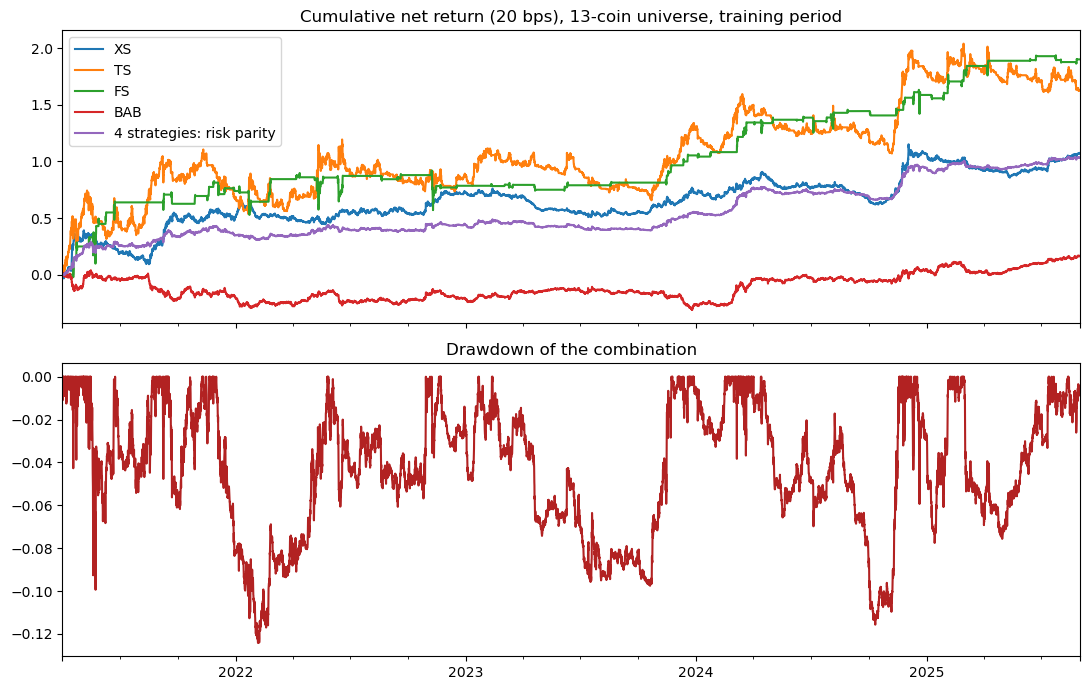

In [31]:
final_name = '4 strategies: risk parity'          # updated below if the decision rule drops TS
gain = sharpe(combos['3 (no TS): risk parity']) - sharpe(combos['4 strategies: risk parity'])
print(f'risk parity without TS minus with TS: {gain:+.3f} Sharpe ->', 'drop TS' if gain >= 0.1 else 'keep TS')
if gain >= 0.1:
    final_name = '3 (no TS): risk parity'
final = combos[final_name]

display(perf(final, mkt).round(3).to_frame(final_name))
display(pd.DataFrame({'vs equal-weight market': alpha_beta(final, mkt), 'vs BTC': alpha_beta(final, btc)}).round(3))

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
combos[['XS', 'TS', 'FS', 'BAB', final_name]].cumsum().plot(ax=ax[0], title='Cumulative net return (20 bps), 13-coin universe, training period')
cum = final.cumsum()
(cum - cum.cummax()).plot(ax=ax[1], color='firebrick', title='Drawdown of the combination')
plt.tight_layout()

**Conclusion (training period, Apr-2021 → Aug-2025).**
- The four strategies are nearly uncorrelated (largest: XS–TS 0.20, TS–FS −0.17).
- **Risk parity is the best realistic method: 4 strategies → Sharpe 1.41**, annual return 16% (252-day convention), vol 12%, max drawdown −12%; full-sample max Sharpe (upper bound) 1.47; equal weights 1.24; rolling max Sharpe 1.10.
- **TS is kept** (removing it lowers the Sharpe to 1.36); without BAB 1.38. BAB still gets the largest risk-parity share (~38%) because of its low vol.
- **Market-neutral**: beta 0.05 to the market and 0.06 to BTC. **Alpha vs BTC ≈ 15% per year, t-stat 3.4**.
- Positive every year (0.65–2.24).
- Higher than the 30-coin version (1.15), but partly because the 13 coins were chosen knowing they would stay liquid until 2025.


## 11. Test period (Sep-2025 → Oct-2026)

Same code and settings as chosen in Sections 2–10, now on the full data. Every signal only uses past data, so the training-period results must be unchanged (checked below).

*Caveat:* the 13-coin strategy of `project_final_v2.ipynb` was designed on Binance.US data up to Dec-2025 and its 2025–2026 results on Binance global were seen before this notebook was written. Here every choice is remade on the training period by the same rules as the 30-coin version, but this knowledge cannot be removed: **the first truly unseen data start in Nov-2026**.

In [32]:
# switch to the full data (training + test)
ret = ret_all.loc[:, univ_all.any()]
univ = univ_all[ret.columns]
ew = equal_weight(univ)
mkt = (ew.shift(1)*ret).sum(axis=1)
btc = ret['BTCUSDT']
daily = ret.index.hour == 0
monthly = (ret.index.day == 1) & daily

W_xs_all = rolling_opt(xs_momentum_mhva(ret, univ), ret, univ, tc_penalty=0.003)          # ~1 minute
ts_all = (ts_signal(mkt) if TS_VARIANT == 'A' else ts_signal_current(ret, univ))['average 7-60d']
w_bab_all, beta_all = betting_against_beta(ret, mkt, univ) if BAB_BETA == 'market' else betting_against_beta_to(ret, btc, univ)
held_all = {'XS':  W_xs_all.reindex(ret.index).ffill().shift(2),
            'TS':  hold_at(ew.mul(ts_all, axis=0), daily).shift(2),
            'FS':  fire_sale(mkt, ew, 2.0)[0].shift(1),
            'BAB': hold_at(w_bab_all, monthly).shift(1)}
R_all = pd.DataFrame({k: (lambda g, t: g - COST*t)(*backtest(h, ret)) for k, h in held_all.items()})
R_all = R_all.loc[ts_all.first_valid_index() + pd.Timedelta('1D'):]
final_cols = SETS['4 strategies'] if final_name.startswith('4') else SETS['3 (no TS)']
R_all['final'] = (risk_parity(R_all, final_cols)*R_all[final_cols]).sum(axis=1)

# check: the training period is reproduced exactly
assert np.allclose(R_all.loc[EVAL_START:TRAIN_END, ['XS', 'TS', 'FS', 'BAB']], R.loc[EVAL_START:TRAIN_END, ['XS', 'TS', 'FS', 'BAB']])
assert np.allclose(R_all.loc[EVAL_START:TRAIN_END, 'final'], combos[final_name].loc[:TRAIN_END])
print('check passed: training-period results reproduced on the full data')

check passed: training-period results reproduced on the full data


In [33]:
# check: price gaps of selected coins in the test period (the stop rule must not trigger on short gaps)
sel = univ.groupby(univ.index.to_period('M')).transform('any')     # coins selected for the month
miss = (sel & ret.isna()).loc[TEST_START:]
gaps = []
for c in miss.columns[miss.any()]:
    s = miss[c]
    g = (s != s.shift()).cumsum()[s]
    for _, grp in s[s].groupby(g):
        gaps.append({'coin': c, 'start': grp.index[0], 'bars': len(grp), 'stops for good': ret[c].loc[grp.index[0]:].notna().sum() == 0})
gaps = pd.DataFrame(gaps)
display(gaps if len(gaps) else 'no gaps')
wide = ret.loc[TEST_START:].notna().where(sel.loc[TEST_START:]).mean(axis=1) < 0.5
print('bars where most selected coins have no price:', int(wide.sum()))

'no gaps'

bars where most selected coins have no price: 0


In [34]:
periods = {'training (Apr-2021 → Aug-2025)': (EVAL_START, TRAIN_END),
           'TEST (Sep-2025 → Oct-2026)':      (TEST_START, None),
           '  Sep–Dec 2025':                  ('2025-09', '2025-12'),
           '  2026 Jan–Oct':                  ('2026-01', '2026-10')}
res = {}
for p, (a, b) in periods.items():
    x = R_all.loc[a:b, 'final']
    ab = alpha_beta(x, btc)
    res[p] = pd.concat([perf(x, mkt), ab.rename({'beta': 'beta to BTC', 'annual alpha': 'alpha vs BTC', 't-stat (alpha)': 't-stat alpha vs BTC'})])
display(pd.DataFrame(res).T.round(3).style.format('{:.3f}').set_caption('Final strategy (4 strategies, risk parity), net of 20 bps'))
display(pd.DataFrame({p: sharpe(R_all.loc[a:b]) for p, (a, b) in periods.items()}).T.round(2).rename_axis('net Sharpe'))
n = to_daily(R_all.loc[TEST_START:, 'final']).shape[0]
print(f'test period: {n} days, standard error of the Sharpe ratio ≈ {np.sqrt(DAYS_PER_YEAR/n):.2f}')

,Sharpe,annual return,annual vol,max drawdown,beta,beta to BTC,alpha vs BTC,t-stat alpha vs BTC
training (Apr-2021 → Aug-2025),1.409,0.162,0.115,-0.124,0.053,0.059,0.150,3.399
TEST (Sep-2025 → Oct-2026),0.845,0.056,0.066,-0.060,0.007,0.021,0.058,1.162
Sep–Dec 2025,3.066,0.210,0.068,-0.022,-0.008,0.005,0.212,2.153
2026 Jan–Oct,-0.098,-0.006,0.064,-0.060,0.018,0.026,-0.005,-0.090


,XS,TS,FS,BAB,final
net Sharpe,,,,,
training (Apr-2021 → Aug-2025),0.84,0.53,1.01,0.19,1.41
TEST (Sep-2025 → Oct-2026),-0.32,0.05,0.75,1.00,0.84
Sep–Dec 2025,1.28,0.06,2.42,1.42,3.07
2026 Jan–Oct,-1.13,0.04,0.02,0.83,-0.10


test period: 426 days, standard error of the Sharpe ratio ≈ 0.77


,market (13 coins),BTC,XS,TS,FS,BAB,final
month (return %),,,,,,,
2025-09,3.0,5.5,3.4,2.2,1.7,-0.1,1.5
2025-10,-14.1,-3.2,4.3,-7.1,18.4,4.4,5.9
2025-11,-22.4,-18.3,-1.4,10.9,-4.4,-1.9,-0.9
2025-12,-11.2,-2.2,2.6,-4.7,9.4,3.8,3.7
2026-01,-13.0,-10.1,-4.5,7.7,-1.6,-3.1,-2.3
2026-02,-9.8,-14.7,5.5,1.7,-3.3,-4.5,-0.8
2026-03,-1.6,2.8,-1.0,-4.2,0.8,3.1,0.8
2026-04,4.8,11.8,-4.2,-12.1,0.0,1.4,-1.7
2026-05,3.9,-3.2,2.4,-2.5,3.8,9.4,5.1


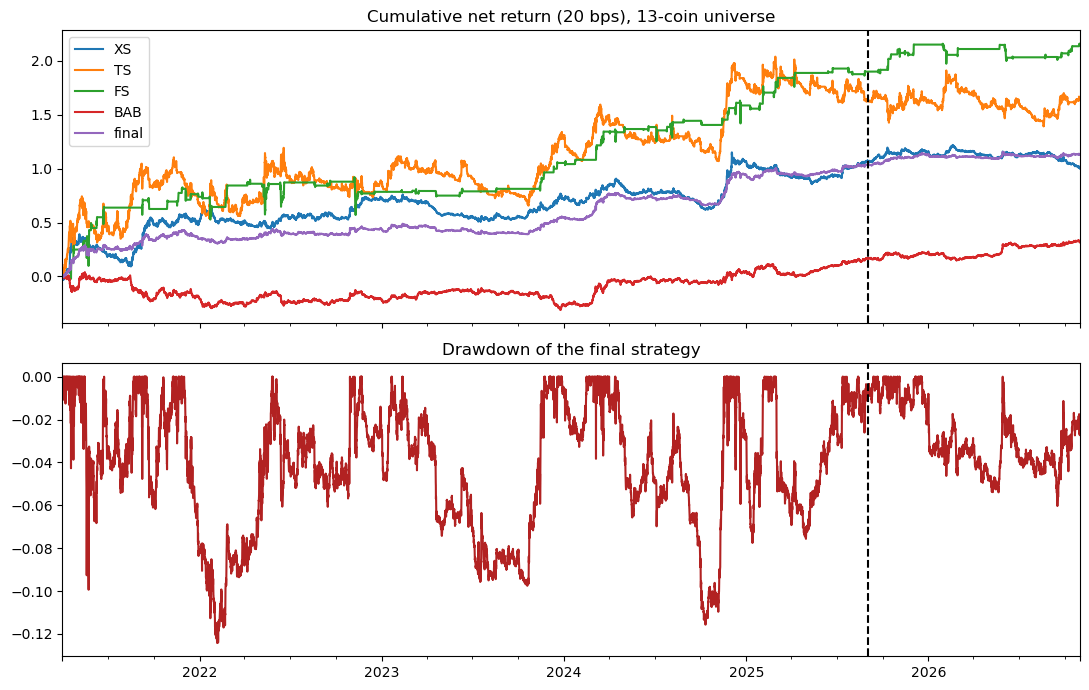

In [35]:
# market context and monthly returns in the test period (%)
test = R_all.loc[TEST_START:]
mon = pd.concat({'market (13 coins)': mkt.loc[TEST_START:], 'BTC': btc.loc[TEST_START:], **{c: test[c] for c in ['XS', 'TS', 'FS', 'BAB', 'final']}}, axis=1)
display((mon.groupby(mon.index.to_period('M')).sum()*100).round(1).rename_axis('month (return %)'))

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
R_all.loc[EVAL_START:].cumsum().plot(ax=ax[0], title='Cumulative net return (20 bps), 13-coin universe')
ax[0].axvline(pd.Timestamp(TEST_START), color='k', ls='--')
cum = R_all.loc[EVAL_START:, 'final'].cumsum()
(cum - cum.cummax()).plot(ax=ax[1], color='firebrick', title='Drawdown of the final strategy')
ax[1].axvline(pd.Timestamp(TEST_START), color='k', ls='--')
plt.tight_layout()

### 11.1 What happened in 2026

**BAB legs:** equal-weight returns of the low-beta and high-beta halves (as selected by BAB each month), their betas, and their beta-adjusted returns (alpha vs the equal-weight market, daily regression).

In [36]:
lo = beta_all.rank(axis=1, pct=True) <= 0.5
hi = ~lo & beta_all.notna()
lo_m = lo[monthly].reindex(ret.index).ffill().shift(1).fillna(False)
hi_m = hi[monthly].reindex(ret.index).ffill().shift(1).fillna(False)
legs = pd.DataFrame({'low-beta half': ret.where(lo_m).mean(axis=1), 'high-beta half': ret.where(hi_m).mean(axis=1)}).fillna(0)

diag = {}
for p, (a, b) in {'training': (EVAL_START, TRAIN_END), 'Sep–Dec 2025': ('2025-09', '2025-12'), '2026 Jan–Oct': ('2026-01', '2026-10')}.items():
    row = {}
    for leg in legs:
        ab = alpha_beta(legs[leg].loc[a:b], mkt)
        row[(leg, 'beta')] = ab['beta']
        row[(leg, 'alpha % / yr')] = ab['annual alpha']*100
    row[('ex-ante beta', 'low')] = beta_all.where(lo)[monthly].loc[a:b].mean(axis=1).mean()
    row[('ex-ante beta', 'high')] = beta_all.where(hi)[monthly].loc[a:b].mean(axis=1).mean()
    diag[p] = row
display(pd.DataFrame(diag).T.round(2))
m26 = pd.concat({'market': mkt, **{c: legs[c] for c in legs}, 'BAB': R_all['BAB']}, axis=1).loc['2026']
(m26.groupby(m26.index.month).sum()*100).round(1).rename_axis('2026 month (return %)')

low-beta half              high-beta half              ex-ante beta      
                      beta alpha % / yr           beta alpha % / yr          low  high
training              0.85         1.46           1.13        -1.26         0.81  1.16
Sep–Dec 2025          0.84        17.77           1.13       -15.23         0.80  1.17
2026 Jan–Oct          0.85         7.88           1.12        -6.75         0.84  1.14

,market,low-beta half,high-beta half,BAB
2026 month (return %),,,,
1,-13.0,-14.2,-11.9,-3.1
2,-9.8,-13.2,-6.8,-4.5
3,-1.6,1.9,-4.6,3.1
4,4.8,5.7,4.0,1.4
5,3.9,13.5,-4.4,9.4
6,-26.2,-24.1,-28.0,-2.0
7,3.6,3.1,4.0,0.1
8,20.9,17.8,23.6,0.7
9,23.6,20.3,26.4,1.5


**Momentum diagnostics** (as in Section 11.1 of `project_final_v2.ipynb`): market return, cross-sectional dispersion of 30-day returns, average pairwise correlation, rank IC of past 30-day returns for the next 30 days, and the number of changes of the 30-day market trend.

In [37]:
pxd = px_all.resample('1D').last()
rd = pxd.pct_change(fill_method=None)
r30 = pxd.pct_change(30, fill_method=None)
ic = r30.rank(axis=1).corrwith(r30.shift(-30).rank(axis=1), axis=1)
diag_m = {}
for y in range(2021, 2027):
    s = str(y)
    c = rd.loc[s].corr().values
    diag_m[y] = {'market return': (1 + rd.loc[s].mean(axis=1)).prod() - 1,
                 'cross-sectional dispersion (30d)': r30.loc[s].std(axis=1).mean(),
                 'average pairwise correlation': c[np.triu_indices_from(c, 1)].mean(),
                 'rank IC (past 30d -> next 30d)': ic.loc[s].mean(),
                 '30d market trend changes': (np.sign(rd.mean(axis=1).rolling(30).sum()).loc[s].diff().abs() > 0).sum()/2}
pd.DataFrame(diag_m).T.round(3)

,market return,cross-sectional dispersion (30d),average pairwise correlation,rank IC (past 30d -> next 30d),30d market trend changes
2021,12.206,0.547,0.494,-0.020,11.5
2022,-0.739,0.129,0.763,-0.093,18.0
2023,1.355,0.149,0.579,0.070,9.5
2024,0.951,0.226,0.565,-0.033,17.5
2025,-0.419,0.113,0.741,-0.013,11.0
2026,-0.223,0.090,0.681,-0.117,23.0


**Conclusion (test period, Sep-2025 → Oct-2026).**
- **Checks passed**: the training results are reproduced exactly; no price gaps in the test period.
- **Final strategy: net Sharpe 0.84** (annual return 5.6%, vol 7%, max drawdown −6%, beta to BTC 0.02, alpha vs BTC t-stat 1.2). **Sep–Dec 2025: 3.07; 2026 Jan–Oct: −0.10.** Standard error ≈ 0.8.
- **In 2026 XS momentum failed (−1.13)**, while BAB worked (+0.83) and FS and TS were flat. The momentum diagnostics show why: in 2026 the cross-sectional dispersion of the 13 coins was the lowest of all years (0.09), last month's winners became next month's losers (rank IC −0.12, the lowest), and the market trend changed direction 23 times (the most).
- **BAB worked with 13 coins**: the low-beta half kept a positive beta-adjusted return in 2026 (+7.9% a year vs −6.8% for the high-beta half), unlike the 30-coin universe, where speculative high-beta coins led every rebound.
- **The two universes fail in opposite places in 2026**: 13 coins → XS fails, BAB works; 30 coins → XS works (+1.09), BAB fails (−2.82). In both cases diversification across the four strategies limited the damage.


## 12. Handling strategy failure: rolling max-Sharpe weights and a 30% cap

Same methods as Section 12 of `30coins_project.ipynb`. Risk parity looks only at volatility, so a strategy that keeps losing at low volatility keeps its share. Two responses, compared with the baseline:

| method | rule |
|---|---|
| **baseline** | risk parity (1-year vol), the final strategy |
| **cap 30%** | risk-parity shares capped at 30% per strategy; the excess stays in cash |
| **rolling max Sharpe** | $w \propto \Sigma^{-1}\mu$ on all past data (≥ 1 year), negative weights set to 0, updated weekly (Section 9): the weights look at past *returns*, so a strategy that keeps losing is cut |
| *equal weight* | 1/4 each, for reference |

Shares are updated once a day; **every method pays 20 bps on the change of each share**.

**How to read it:** the training period shows the cost of each method in normal times. These methods were chosen after the 2026 results of the 30-coin version were known, so **the test results are post-hoc**.

In [38]:
daily_t = R_all.index[R_all.index.hour == 0]
cols4 = ['XS', 'TS', 'FS', 'BAB']
Rs = R_all[cols4]
base = risk_parity(Rs, cols4)
shares = {'baseline (risk parity)': base,
          'cap 30%':                base.clip(upper=0.30),
          'rolling max Sharpe':     rolling_max_sharpe(Rs, cols4),
          'equal weight':           pd.DataFrame(0.25, index=Rs.index, columns=cols4)}

port, Wsh = {}, {}
for name, w in shares.items():
    port[name], Wsh[name] = run_shares(w, Rs, daily_t)
port = pd.DataFrame(port)

tr = pd.DataFrame({n: summary(port[n], EVAL_START, TRAIN_END) for n in port}).T
tr['avg invested share'] = [Wsh[n].loc[EVAL_START:TRAIN_END].sum(axis=1).mean() for n in port]
display(tr.round(3).style.format('{:.3f}').set_caption('Training period (Apr-2021 → Aug-2025): cost in normal times'))
display(pd.DataFrame({p: sharpe(port.loc[a:b]) for p, (a, b) in periods.items()}).round(2).style.format('{:.2f}')
        .set_caption('Net Sharpe by period (test columns are post-hoc)'))

,Sharpe,annual return,max drawdown,worst year Sharpe,avg invested share
baseline (risk parity),1.410,0.162,-0.125,0.638,1.000
cap 30%,1.413,0.157,-0.120,0.660,0.912
rolling max Sharpe,1.080,0.132,-0.150,0.554,1.000
equal weight,1.235,0.186,-0.153,0.523,1.000


,training (Apr-2021 → Aug-2025),TEST (Sep-2025 → Oct-2026),Sep–Dec 2025,2026 Jan–Oct
baseline (risk parity),1.41,0.83,3.05,-0.11
cap 30%,1.41,0.75,3.12,-0.26
rolling max Sharpe,1.08,0.66,3.00,-0.36
equal weight,1.23,0.62,2.21,-0.11


baseline (risk parity)       cap 30%      rolling max Sharpe       equal weight      
                                                     XS   BAB      XS  BAB                 XS   BAB           XS   BAB
average share in the test period                                                                                      
2025-09                                            0.27  0.41    0.27  0.3               0.36  0.31         0.25  0.25
2025-10                                            0.27  0.42    0.27  0.3               0.36  0.31         0.25  0.25
2025-11                                            0.28  0.42    0.28  0.3               0.36  0.31         0.25  0.25
2025-12                                            0.31  0.42    0.30  0.3               0.36  0.31         0.25  0.25
2026-01                                            0.30  0.41    0.30  0.3               0.35  0.31         0.25  0.25
2026-02                                            0.30  0.41    0.30  0.3               0.36  0.30         0.25  0.25
2026-03                                            0.29  0.42    0.29  0.3               0.36  0.30         0.25  0.25
2026-04                                            0.28  0.42    0.28  0.3               0.36  0.30         0.25  0.25
2026-05                                            0.28  0.42    0.28  0.3               0.35  0.31         0.25  0.25
2026-06                                            0.28  0.41    0.28  0.3               0.35  0.33         0.25  0.25
2026-07                                            0.29  0.40    0.29  0.3               0.35  0.33         0.25  0.25
2026-08                                            0.30  0.40    0.30  0.3               0.36  0.33         0.25  0.25
2026-09                                            0.30  0.40    0.30  0.3               0.35  0.33         0.25  0.25
2026-10                                            0.30  0.39    0.30  0.3               0.33  0.34         0.25  0.25

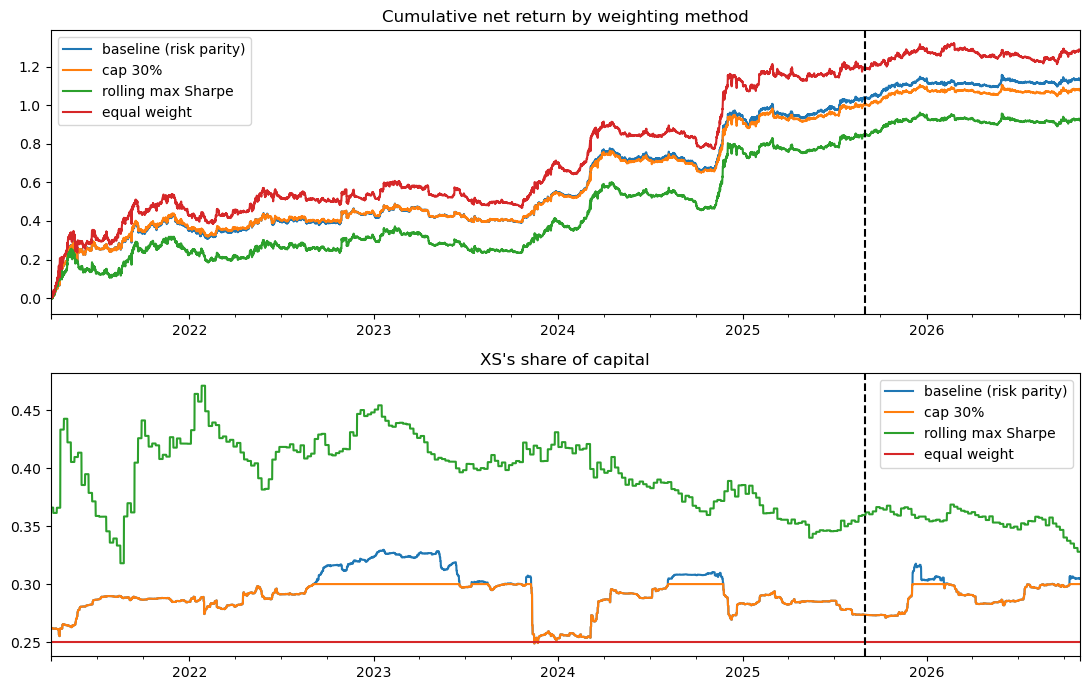

In [39]:
# BAB's share of capital by month in the test period
sh = pd.concat({n: Wsh[n][['XS', 'BAB']] for n in Wsh}, axis=1).loc[TEST_START:]
display(sh.groupby(sh.index.to_period('M')).mean().round(2).rename_axis('average share in the test period'))

fig, ax = plt.subplots(2, 1, figsize=(11, 7))
port.loc[EVAL_START:].cumsum().plot(ax=ax[0], title='Cumulative net return by weighting method')
ax[0].axvline(pd.Timestamp(TEST_START), color='k', ls='--')
pd.DataFrame({n: Wsh[n]['XS'] for n in Wsh}).loc[EVAL_START:].plot(ax=ax[1], title="XS's share of capital")
ax[1].axvline(pd.Timestamp(TEST_START), color='k', ls='--')
plt.tight_layout()

**Conclusion.**
- **Training period:** the cap is free (1.413 vs 1.410); rolling max Sharpe costs 0.33 (1.08); equal weight 1.24.
- **Test period (post-hoc):** baseline 0.83 (2026: −0.11); **cap 30%: 0.75 (−0.26)**; **rolling max Sharpe: 0.66 (−0.36)**; equal weight 0.62 (−0.11).
- **Here both methods make things worse.** The strategy that failed in 2026 is XS, whose share (~29%) is below the cap, so the cap only trimmed BAB, which was working. Rolling max Sharpe gave XS *more* capital (~36%), because XS had the highest past mean return.
- **Lesson:** a cap and return-based weights only help when the failing strategy is the one that holds the most capital (BAB in the 30-coin version). They are not a general cure for strategy failure; diversification across uncorrelated strategies did more here.


## 13. Conclusions and limitations

**Results (13 coins, Binance global, net of 20 bps)**
- **Training (Apr-2021 → Aug-2025): Sharpe 1.41**, beta to BTC 0.06, alpha vs BTC 15% a year (t-stat 3.4).
- **Test (Sep-2025 → Oct-2026): 0.84** (Sep–Dec 2025: 3.07; 2026 Jan–Oct: −0.10).
- Strongest strategies in training: fire sale (1.01) and XS momentum (0.84); TS 0.53; BAB weak (0.19) but a diversifier.

**Compared with the 30-coin point-in-time version (`30coins_project.ipynb`)**
| net Sharpe | 13 coins | 30 coins |
|---|---|---|
| training | 1.41 | 1.15 |
| test | 0.84 | 0.32 |
| 2026 Jan–Oct | −0.10 | −0.72 |
| XS in 2026 | −1.13 | +1.09 |
| BAB in 2026 | +0.83 | −2.82 |

- The 13-coin numbers are higher, but **the 13 coins were chosen with full-sample volume** (survivorship and look-ahead) and the strategy was first designed on data that overlap the test period; the 30-coin version has neither problem. The test difference (0.84 vs 0.32) is below one standard error.
- **Each universe exposed a different weakness in 2026**: with only large coins, cross-sectional momentum had no dispersion to trade; with more speculative coins, the low-beta premium reversed.
- **Risk controls depend on where the failure is**: the 30% cap and rolling max-Sharpe weights helped the 30-coin version (BAB held the most capital) but hurt here (XS failed with a small share).

**What did not work**: short-horizon reversal and pairs trading (profits on Binance.US shrink on Binance global), volume conditioning, BTC as the TS indicator, betas to BTC for BAB.

**Limitations**
- Universe chosen with full-sample Binance.US volume (look-ahead, survivorship).
- The v2 design and its 2025–2026 results were known before this notebook: **the first truly unseen data start in Nov-2026**.
- Many specifications tried on the same training data; costs a single estimate (20 bps); no funding costs for short legs; weight drift ignored.
- Annual returns use the 252-day course convention.
